In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from IPython.display import HTML
from matplotlib.animation import FuncAnimation
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

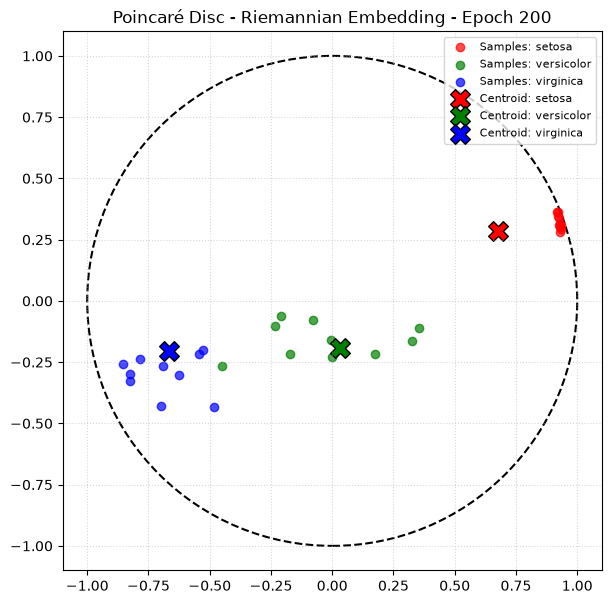

In [2]:
# ==============================================================================
# 1. Preparación de Datos (Iris Dataset)
# ==============================================================================
iris = load_iris()
X, y = iris.data, iris.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.long)

# ==============================================================================
# 2. Funciones Geodésicas en PyTorch Puro
# ==============================================================================
EPS = 1e-5


def project_poincare(
    x: torch.Tensor, max_norm: float = 1.0 - EPS
) -> torch.Tensor:
    norm = torch.norm(x, dim=-1, keepdim=True)
    cond = norm >= max_norm
    rescaled = x / norm * max_norm
    return torch.where(cond, rescaled, x)


def exp_map_zero(v: torch.Tensor) -> torch.Tensor:
    norm = torch.norm(v, dim=-1, keepdim=True)
    norm = torch.clamp(norm, min=1e-10)
    return project_poincare(torch.tanh(norm) * (v / norm))


def poincare_distance_matrix(x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    x = project_poincare(x).unsqueeze(1)
    y = project_poincare(y).unsqueeze(0)

    sq_dist = torch.sum((x - y) ** 2, dim=-1)
    x_sqnorm = torch.sum(x**2, dim=-1)
    y_sqnorm = torch.sum(y**2, dim=-1)

    denom = (1 - x_sqnorm) * (1 - y_sqnorm)
    denom = torch.clamp(denom, min=1e-10)

    arg = 1 + 2 * sq_dist / denom
    arg = torch.clamp(arg, min=1.0 + 1e-7)

    return torch.acosh(arg)


# ==============================================================================
# 3. Modelo y Optimizador Riemanniano
# ==============================================================================
class PoincareIrisClassifier(nn.Module):

    def __init__(
        self, in_features: int = 4, embed_dim: int = 2, num_classes: int = 3
    ):
        super().__init__()
        self.fc = nn.Linear(in_features, embed_dim)
        centroids_init = torch.randn(num_classes, embed_dim) * 1e-2
        self.centroids = nn.Parameter(project_poincare(centroids_init))

    def forward(self, x: torch.Tensor):
        v = self.fc(x)
        z = exp_map_zero(v)
        centroids_proj = project_poincare(self.centroids)
        dists = poincare_distance_matrix(z, centroids_proj)
        return -dists, z


def riemannian_step(param: nn.Parameter, lr: float):
    if param.grad is None:
        return
    with torch.no_grad():
        sq_norm = torch.sum(param.data**2, dim=-1, keepdim=True)
        scale_factor = ((1 - sq_norm) ** 2) / 4.0
        r_grad = scale_factor * param.grad
        param.data -= lr * r_grad
        param.data = project_poincare(param.data)
        param.grad.zero_()


# ==============================================================================
# 4. Entrenamiento y Captura de Historial
# ==============================================================================
model = PoincareIrisClassifier(in_features=4, embed_dim=2, num_classes=3)
optimizer_euclidean = optim.Adam(model.fc.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()
lr_riemannian = 0.05

# Estructura para guardar las posiciones por época: (época, z_test, centroides)
history = []

epochs = 200
for epoch in range(1, epochs + 1):
    model.train()
    optimizer_euclidean.zero_grad()
    if model.centroids.grad is not None:
        model.centroids.grad.zero_()

    logits, _ = model(X_train)
    loss = criterion(logits, y_train)
    loss.backward()

    optimizer_euclidean.step()
    riemannian_step(model.centroids, lr=lr_riemannian)

    # Capturar coordenadas del conjunto de test cada 2 épocas
    if epoch % 2 == 0 or epoch == 1:
        model.eval()
        with torch.no_grad():
            _, z_test_eval = model(X_test)
            centroids_eval = project_poincare(model.centroids).clone()
            history.append(
                (epoch, z_test_eval.numpy(), centroids_eval.numpy())
            )

# ==============================================================================
# 5. Generación de la Animación
# ==============================================================================
fig, ax = plt.subplots(figsize=(7, 7))

# Círculo unitario de la Bola de Poincaré
circle = plt.Circle(
    (0, 0), 1.0, color="black", fill=False, linestyle="--", linewidth=1.5
)
ax.add_patch(circle)

colors = ["red", "green", "blue"]
y_test_np = y_test.numpy()

# Inicialización de los elementos gráficos en el scatter plot
scat_points = []
scat_centroids = []

# Puntos de datos por clase
for i, name in enumerate(iris.target_names):
    scat = ax.scatter(
        [], [], c=colors[i], label=f"Samples: {name}", alpha=0.7
    )
    scat_points.append(scat)

# Centroides por clase
for i, name in enumerate(iris.target_names):
    scat_c = ax.scatter(
        [],
        [],
        c=colors[i],
        marker="X",
        s=200,
        edgecolors="black",
        label=f"Centroid: {name}",
    )
    scat_centroids.append(scat_c)

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="upper right", fontsize=8)

title_text = ax.set_title("Poincaré Disk - Riemannian Embedding - Epoch 0")


def update(frame):
    ep, z_vals, c_vals = history[frame]

    # Actualizar puntos de prueba según su clase
    for i in range(3):
        mask = y_test_np == i
        scat_points[i].set_offsets(z_vals[mask])
        scat_centroids[i].set_offsets(c_vals[i : i + 1])

    title_text.set_text(f"Poincaré Disc - Riemannian Embedding - Epoch {ep:03d}")
    return scat_points + scat_centroids + [title_text]


# Crear objeto de animación
anim = FuncAnimation(
    fig, update, frames=len(history), interval=60, blit=True
)

# Guardar o mostrar animación
# plt.show()

# Guardar como GIF (requiere 'pillow' o 'imagemagick')
anim.save("poincare_calibration.gif", writer="pillow", fps=15)

# Renderizar directamente en Google Colab / Jupyter Notebook:
HTML(anim.to_jshtml())

In [3]:
loss

tensor(0.2879, grad_fn=<NllLossBackward0>)